# KOA Severity Classification: Ordinal ConvNeXt-Small + PCA + LinearSVC

This notebook implements the **current proposed pipeline** used in the accompanying Persian research manuscript.

## Workflow
1. Load the previously trained ordinal ConvNeXt-Small checkpoint.
2. Download the public Kaggle dataset with KaggleHub.
3. Extract fixed 768-dimensional features for Train and Validation.
4. Fit PCA on **Train only**, retaining 95% of training-feature variance.
5. Select `LinearSVC` hyperparameters using **Validation only**.
6. Evaluate the frozen direct ordinal model and the selected hybrid pipeline on Test.
7. Run paired patient-level cluster bootstrap on the stored Test predictions.

## Before running
- Runtime: Google Colab (GPU recommended for feature extraction).
- Place `best_ordinal_convnext.pth` at `/content/drive/MyDrive/best_ordinal_convnext.pth`.
- The checkpoint and dataset are intentionally not committed to this repository.
- The `auto_test` split is not loaded or evaluated in this notebook.
- Do not use Test results to select or retune models. SVM configuration selection uses Validation Macro F1 (QWK as tie-breaker); ROC-AUC is reported as a complementary measure.
- The Test predictions and AUC scores are saved under the dedicated `KOA_OrdinalConvNeXt_PCA_SVM_v1_REPRO_TEST` folder to avoid overwriting older Drive artifacts.

**Research caveat:** older exploratory notebooks in this repository document additional model configurations; some historical experiments used Test labels during experimentation. See `docs/NOTEBOOK_CLEANUP_REPORT.md` before interpreting the overall project history as an independent benchmark.

## 1. Environment and paths

The next cell installs the small number of additional packages used by this notebook. PyTorch and torchvision are normally preinstalled in Google Colab.

In [ ]:
%pip -q install timm kagglehub joblib

In [ ]:
from pathlib import Path
import json
import re
from collections import defaultdict

import joblib
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import timm
import torch
import torch.nn as nn
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    cohen_kappa_score,
    confusion_matrix,
    f1_score,
)
from sklearn.svm import LinearSVC
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from tqdm.auto import tqdm

from google.colab import drive

drive.mount('/content/drive')

CHECKPOINT_PATH = Path('/content/drive/MyDrive/best_ordinal_convnext.pth')
OUTPUT_DIR = Path('/content/drive/MyDrive/KOA_OrdinalConvNeXt_PCA_SVM_v1_REPRO_TEST')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DATASET_HANDLE = 'shashwatwork/knee-osteoarthritis-dataset-with-severity/versions/1'
MODEL_NAME = 'convnext_small.fb_in22k_ft_in1k_384'
IMAGE_SIZE = 384
BATCH_SIZE = 16
NUM_CLASSES = 5
CLASS_NAMES = ['KL0', 'KL1', 'KL2', 'KL3', 'KL4']
CLASS_LABELS = np.arange(NUM_CLASSES)
RANDOM_SEED = 42

if not CHECKPOINT_PATH.is_file():
    raise FileNotFoundError(
        f'Model checkpoint not found: {CHECKPOINT_PATH}\n'
        'Upload/copy the trained checkpoint to the documented Google Drive path.'
    )

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__)
print('Device:', DEVICE)
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))

Mounted at /content/drive
PyTorch: 2.11.0+cu130
Device: cuda
GPU: Tesla T4


## 2. Load the trained ordinal ConvNeXt checkpoint

The backbone is **not trained again** here. This section recreates the saved architecture and loads the checkpoint strictly, so a mismatch in tensor names or shapes stops execution.

In [ ]:
class OrdinalConvNeXt(nn.Module):
    def __init__(self, model_name: str, drop_path_rate: float = 0.2):
        super().__init__()
        self.backbone = timm.create_model(
            model_name,
            pretrained=False,
            num_classes=0,
            drop_path_rate=drop_path_rate,
        )
        self.head = nn.Linear(self.backbone.num_features, 4)

    def forward(self, x):
        features = self.backbone(x)
        logits = self.head(features)
        return logits, features


checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location='cpu',
    weights_only=True,
)

if isinstance(checkpoint, dict) and 'model_state_dict' in checkpoint:
    state_dict = checkpoint['model_state_dict']
elif isinstance(checkpoint, dict) and 'state_dict' in checkpoint:
    state_dict = checkpoint['state_dict']
else:
    state_dict = checkpoint

if not isinstance(state_dict, dict) or not all(
    torch.is_tensor(value) for value in state_dict.values()
):
    raise TypeError('Checkpoint is not a plain model state_dict or a supported wrapper.')

model = OrdinalConvNeXt(MODEL_NAME, drop_path_rate=0.2)
model.load_state_dict(state_dict, strict=True)
model = model.to(DEVICE)
model.eval()

print('Checkpoint loaded with strict=True.')
print('Backbone feature dimension:', model.backbone.num_features)
print('Ordinal output dimension:', model.head.out_features)

Checkpoint loaded with strict=True.
Backbone feature dimension: 768
Ordinal output dimension: 4


## 3. Download and inspect Train/Validation/Test

The dataset is downloaded through KaggleHub. Only the `train`, `val`, and `test` directories are accessed; `auto_test` is intentionally excluded.

In [ ]:
DATASET_PATH = Path(kagglehub.dataset_download(DATASET_HANDLE))
REQUIRED_SPLITS = ('train', 'val', 'test')


def has_required_splits(path: Path) -> bool:
    return path.is_dir() and all((path / split).is_dir() for split in REQUIRED_SPLITS)


if has_required_splits(DATASET_PATH):
    DATASET_ROOT = DATASET_PATH
else:
    candidates = [p for p in DATASET_PATH.iterdir() if has_required_splits(p)]
    if len(candidates) != 1:
        raise RuntimeError(
            'Could not identify exactly one dataset root containing train/val/test. '
            f'Found: {[str(p) for p in candidates]}'
        )
    DATASET_ROOT = candidates[0]

print('Dataset root:', DATASET_ROOT)

for split in REQUIRED_SPLITS:
    split_path = DATASET_ROOT / split
    num_images = sum(
        1 for p in split_path.rglob('*')
        if p.is_file() and p.suffix.lower() in {'.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff'}
    )
    print(f'{split}: {num_images:,} images')

100%|██████████| 204M/204M [00:01<00:00, 134MB/s]

Extracting files...


Dataset root: /root/.cache/kagglehub/datasets/shashwatwork/knee-osteoarthritis-dataset-with-severity/versions/1
train: 5,778 images
val: 826 images
test: 1,656 images


In [ ]:
FEATURE_TRANSFORM = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

train_dataset = datasets.ImageFolder(
    root=str(DATASET_ROOT / 'train'),
    transform=FEATURE_TRANSFORM,
)
val_dataset = datasets.ImageFolder(
    root=str(DATASET_ROOT / 'val'),
    transform=FEATURE_TRANSFORM,
)
EXPECTED_CLASS_MAPPING = {'0': 0, '1': 1, '2': 2, '3': 3, '4': 4}

assert train_dataset.class_to_idx == EXPECTED_CLASS_MAPPING, train_dataset.class_to_idx
assert val_dataset.class_to_idx == EXPECTED_CLASS_MAPPING, val_dataset.class_to_idx
assert len(train_dataset) == 5778, f'Unexpected Train size: {len(train_dataset)}'
assert len(val_dataset) == 826, f'Unexpected Validation size: {len(val_dataset)}'

print('Train class mapping:', train_dataset.class_to_idx)
print('Validation class mapping:', val_dataset.class_to_idx)
print('Class mappings and expected split sizes verified.')

Train class mapping: {'0': 0, '1': 1, '2': 2, '3': 3, '4': 4}
Validation class mapping: {'0': 0, '1': 1, '2': 2, '3': 3, '4': 4}
Class mappings and expected split sizes verified.


## 4. Extract fixed features

Images are resized and ImageNet-normalized. Feature extraction runs in evaluation mode without gradients, and the ConvNeXt weights remain unchanged. The DataLoaders use `shuffle=False` to preserve deterministic dataset ordering.

In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(DEVICE.type == 'cuda'),
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(DEVICE.type == 'cuda'),
)


@torch.inference_mode()
def extract_features(feature_model, loader, device, description):
    feature_model.eval()
    features_list, labels_list = [], []

    for images, labels in tqdm(loader, desc=description):
        images = images.to(device, non_blocking=True)
        _, features = feature_model(images)
        features_list.append(features.cpu().numpy().astype(np.float32, copy=False))
        labels_list.append(labels.numpy().astype(np.int64, copy=False))

    if not features_list:
        raise RuntimeError(f'No images found while {description.lower()}.')

    return np.concatenate(features_list), np.concatenate(labels_list)


X_train_features, y_train = extract_features(
    model, train_loader, DEVICE, 'Extracting Train features'
)
X_val_features, y_val = extract_features(
    model, val_loader, DEVICE, 'Extracting Validation features'
)

assert X_train_features.shape == (5778, 768), X_train_features.shape
assert X_val_features.shape == (826, 768), X_val_features.shape
assert y_train.shape == (5778,) and y_val.shape == (826,)

print('Train feature matrix:', X_train_features.shape)
print('Validation feature matrix:', X_val_features.shape)
print('Feature extraction complete; ConvNeXt weights were not updated.')

Extracting Train features:   0%|          | 0/362 [00:00<?, ?it/s]

Extracting Validation features:   0%|          | 0/52 [00:00<?, ?it/s]

Train feature matrix: (5778, 768)
Validation feature matrix: (826, 768)
Feature extraction complete; ConvNeXt weights were not updated.


## 5. Fit PCA on Train and select LinearSVC on Validation

PCA is fitted only on training features. The same fitted transform is applied to Validation. The hyperparameter search ranks configurations by Validation Macro F1, using QWK as the secondary sorting criterion.

In [ ]:
pca = PCA(n_components=0.95, svd_solver='full')
X_train_pca = pca.fit_transform(X_train_features)
X_val_pca = pca.transform(X_val_features)

print('Feature dimensions:', X_train_features.shape[1], '->', X_train_pca.shape[1])
print('Training variance retained:', f'{pca.explained_variance_ratio_.sum():.6f}')

C_VALUES = [0.01, 0.1, 1.0, 10.0, 100.0]
CLASS_WEIGHT_OPTIONS = [None, 'balanced']
search_rows = []
svm_models = {}

for class_weight in CLASS_WEIGHT_OPTIONS:
    for c_value in C_VALUES:
        candidate = LinearSVC(
            C=c_value,
            class_weight=class_weight,
            random_state=RANDOM_SEED,
            max_iter=20000,
        )
        candidate.fit(X_train_pca, y_train)
        val_pred = candidate.predict(X_val_pca)
        scores = {
            'C': c_value,
            'Class Weight': 'balanced' if class_weight == 'balanced' else 'None',
            'Accuracy': accuracy_score(y_val, val_pred),
            'Macro F1': f1_score(y_val, val_pred, average='macro', zero_division=0),
            'Balanced Accuracy': balanced_accuracy_score(y_val, val_pred),
            'QWK': cohen_kappa_score(y_val, val_pred, weights='quadratic'),
        }
        search_rows.append(scores)
        svm_models[(c_value, class_weight)] = candidate

search_df = pd.DataFrame(search_rows).sort_values(
    ['Macro F1', 'QWK'], ascending=False
).reset_index(drop=True)
best_result = search_df.iloc[0]
best_C = float(best_result['C'])
best_class_weight = 'balanced' if best_result['Class Weight'] == 'balanced' else None
best_svm_model = svm_models[(best_C, best_class_weight)]

search_df.to_csv(OUTPUT_DIR / 'validation_svm_search.csv', index=False)
print(search_df.round(4).to_string(index=False))
print('\nSelected configuration:', {'C': best_C, 'class_weight': best_class_weight})
print('Selection criterion: Validation Macro F1; QWK used as tie-breaker.')

Feature dimensions: 768 -> 59
Training variance retained: 0.950057
     C Class Weight  Accuracy  Macro F1  Balanced Accuracy    QWK
  0.10     balanced    0.7046    0.7198             0.7201 0.8485
  0.10         None    0.7131    0.7152             0.7109 0.8479
  0.01     balanced    0.7022    0.7144             0.7176 0.8453
 10.00     balanced    0.6998    0.7120             0.7141 0.8453
100.00     balanced    0.6998    0.7120             0.7141 0.8453
  1.00         None    0.7119    0.7113             0.7106 0.8484
 10.00         None    0.7119    0.7107             0.7102 0.8486
100.00         None    0.7119    0.7107             0.7102 0.8486
  0.01         None    0.7058    0.7083             0.7038 0.8420
  1.00     balanced    0.6985    0.7078             0.7123 0.8452

Selected configuration: {'C': 0.1, 'class_weight': 'balanced'}
Selection criterion: Validation Macro F1; QWK used as tie-breaker.


## 6. Validation comparison and save development artifacts

The direct model decodes the four ordinal logits by counting outputs greater than zero. The hybrid model uses the selected LinearSVC on PCA-transformed features. The Test set has not been used for model selection.

In [ ]:
y_val_pred_hybrid = best_svm_model.predict(X_val_pca)

@torch.inference_mode()
def predict_direct_ordinal(feature_model, loader, device):
    feature_model.eval()
    predictions = []
    for images, _ in tqdm(loader, desc='Predicting direct ordinal Validation labels'):
        images = images.to(device, non_blocking=True)
        logits, _ = feature_model(images)
        predictions.append((logits > 0).sum(dim=1).cpu().numpy().astype(np.int64))
    return np.concatenate(predictions)


y_val_pred_ordinal = predict_direct_ordinal(model, val_loader, DEVICE)

def calculate_metrics(y_true, y_pred):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Macro F1': f1_score(y_true, y_pred, labels=CLASS_LABELS, average='macro', zero_division=0),
        'Balanced Accuracy': balanced_accuracy_score(y_true, y_pred),
        'QWK': cohen_kappa_score(y_true, y_pred, labels=CLASS_LABELS, weights='quadratic'),
    }


validation_metrics = pd.DataFrame([
    {'Model': 'Direct Ordinal ConvNeXt', **calculate_metrics(y_val, y_val_pred_ordinal)},
    {'Model': 'Proposed Hybrid (PCA + LinearSVC)', **calculate_metrics(y_val, y_val_pred_hybrid)},
])
validation_metrics.to_csv(OUTPUT_DIR / 'validation_metrics.csv', index=False)
print(validation_metrics.round(4).to_string(index=False))

val_predictions = pd.DataFrame({
    'filename': [Path(path).name for path, _ in val_dataset.samples],
    'true_label': y_val,
    'ordinal_prediction': y_val_pred_ordinal,
    'hybrid_prediction': y_val_pred_hybrid,
})
val_predictions.to_csv(OUTPUT_DIR / 'validation_predictions.csv', index=False)

for method_name, predictions in [
    ('ordinal', y_val_pred_ordinal),
    ('hybrid', y_val_pred_hybrid),
]:
    cm = confusion_matrix(y_val, predictions, labels=CLASS_LABELS)
    pd.DataFrame(
        cm,
        index=[f'True_{name}' for name in CLASS_NAMES],
        columns=[f'Pred_{name}' for name in CLASS_NAMES],
    ).to_csv(OUTPUT_DIR / f'validation_confusion_matrix_{method_name}.csv')

joblib.dump(pca, OUTPUT_DIR / 'pca.joblib')
joblib.dump(best_svm_model, OUTPUT_DIR / 'linear_svc.joblib')
np.savez_compressed(
    OUTPUT_DIR / 'extracted_features.npz',
    X_train_features=X_train_features,
    y_train=y_train,
    X_val_features=X_val_features,
    y_val=y_val,
)

metadata = {
    'project': 'KOA Ordinal ConvNeXt + PCA + LinearSVC',
    'dataset_handle': DATASET_HANDLE,
    'torch_version': torch.__version__,
    'timm_version': timm.__version__,
    'backbone': MODEL_NAME,
    'backbone_checkpoint': str(CHECKPOINT_PATH),
    'input_size': [IMAGE_SIZE, IMAGE_SIZE],
    'feature_dimension': int(X_train_features.shape[1]),
    'pca_components': int(pca.n_components_),
    'pca_explained_variance': float(pca.explained_variance_ratio_.sum()),
    'classifier': 'LinearSVC',
    'svm_C': best_C,
    'class_weight': best_class_weight,
    'classes': CLASS_NAMES,
    'train_images': int(len(y_train)),
    'validation_images': int(len(y_val)),
    'validation_metrics': validation_metrics.set_index('Model').to_dict(orient='index'),
    'test_evaluated_in_this_notebook': False,
}
with open(OUTPUT_DIR / 'metadata.json', 'w', encoding='utf-8') as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

print('Development artifacts saved to:', OUTPUT_DIR)

Predicting direct ordinal Validation labels:   0%|          | 0/52 [00:00<?, ?it/s]

                            Model  Accuracy  Macro F1  Balanced Accuracy    QWK
          Direct Ordinal ConvNeXt    0.6961    0.7108             0.7140 0.8585
Proposed Hybrid (PCA + LinearSVC)    0.7046    0.7198             0.7201 0.8485
Development artifacts saved to: /content/drive/MyDrive/KOA_OrdinalConvNeXt_PCA_SVM_v1_REPRO_TEST


## 7. Validation ROC-AUC evaluation

Macro ROC-AUC is reported as a complementary class-discrimination measure using a one-vs-rest (OvR) calculation for the five KL grades. It is **not** used to choose or retune the SVM: the selected `LinearSVC` configuration remains the one chosen by Validation Macro F1, with QWK as the secondary tie-breaker.

For the proposed PCA + LinearSVC method, the class-wise OvR AUC is calculated from the continuous `decision_function` scores. For the direct ordinal baseline, the four threshold logits are converted to cumulative probabilities and then to five class scores. When those cumulative scores violate the expected order, isotonic regression is applied only to the scores used for AUC calculation; the model's hard class predictions are not changed. The count of affected samples is reported by the cell.

In [ ]:

import numpy as np
import pandas as pd
import torch

from scipy.special import expit
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score


# Convert the four ordinal logits to five class-level scores.
def ordinal_logits_to_class_scores(logits):
    cumulative_raw = expit(np.asarray(logits, dtype=float))
    cumulative = cumulative_raw.copy()
    threshold_positions = np.arange(4)

    violations = np.any(
        np.diff(cumulative_raw, axis=1) > 1e-8, axis=1
    )

    isotonic = IsotonicRegression(
        increasing=False,
        out_of_bounds="clip",
    )

    for row_idx in np.flatnonzero(violations):
        cumulative[row_idx] = isotonic.fit_transform(
            threshold_positions,
            cumulative_raw[row_idx],
        )

    class_scores = np.column_stack([
        1 - cumulative[:, 0],
        cumulative[:, 0] - cumulative[:, 1],
        cumulative[:, 1] - cumulative[:, 2],
        cumulative[:, 2] - cumulative[:, 3],
        cumulative[:, 3],
    ])

    class_scores = np.clip(class_scores, 0, 1)
    class_scores /= class_scores.sum(axis=1, keepdims=True)

    return class_scores, int(violations.sum())


def calculate_macro_ovr_auc(y_true, class_scores):
    per_class = []
    for class_idx in range(5):
        y_binary = (np.asarray(y_true) == class_idx).astype(int)
        per_class.append(
            roc_auc_score(y_binary, class_scores[:, class_idx])
        )
    return np.asarray(per_class)


# Extract logits on Validation using the existing checkpoint.
@torch.inference_mode()
def collect_ordinal_logits(feature_model, loader, device):
    feature_model.eval()
    logits_all = []
    labels_all = []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        logits, _ = feature_model(images)
        logits_all.append(logits.cpu().numpy())
        labels_all.append(labels.numpy())

    return np.concatenate(logits_all), np.concatenate(labels_all)


val_logits, y_val_auc = collect_ordinal_logits(
    model, val_loader, DEVICE
)

assert np.array_equal(y_val_auc, y_val)

val_direct_scores, val_violations = ordinal_logits_to_class_scores(
    val_logits
)

# LinearSVC continuous decision scores, not hard class predictions.
val_hybrid_scores = best_svm_model.decision_function(X_val_pca)

val_auc_direct = calculate_macro_ovr_auc(
    y_val, val_direct_scores
)
val_auc_hybrid = calculate_macro_ovr_auc(
    y_val, val_hybrid_scores
)

val_auc_per_class = pd.DataFrame({
    "KL class": CLASS_NAMES,
    "Support": [
        int(np.sum(y_val == i)) for i in CLASS_LABELS
    ],
    "Direct Ordinal ConvNeXt ROC-AUC": val_auc_direct,
    "Proposed Hybrid ROC-AUC": val_auc_hybrid,
})

val_auc_summary = pd.DataFrame([
    {
        "Model": "Direct Ordinal ConvNeXt",
        "Macro ROC-AUC (OvR)": val_auc_direct.mean(),
    },
    {
        "Model": "Proposed Hybrid (PCA + LinearSVC)",
        "Macro ROC-AUC (OvR)": val_auc_hybrid.mean(),
    },
])

print("Validation threshold-order violations:", val_violations)
print("\nPer-class Validation ROC-AUC:")
print(val_auc_per_class.round(4).to_string(index=False))
print("\nMacro Validation ROC-AUC:")
print(val_auc_summary.round(4).to_string(index=False))
print(
    "\nHybrid minus Direct:",
    round(val_auc_hybrid.mean() - val_auc_direct.mean(), 4),
)

val_auc_per_class.to_csv(
    OUTPUT_DIR / "validation_roc_auc_per_class.csv", index=False
)
val_auc_summary.to_csv(
    OUTPUT_DIR / "validation_roc_auc_summary.csv", index=False
)


Validation threshold-order violations: 92

Per-class Validation ROC-AUC:
KL class  Support  Direct Ordinal ConvNeXt ROC-AUC  Proposed Hybrid ROC-AUC
     KL0      328                           0.9135                   0.9110
     KL1      153                           0.7720                   0.7715
     KL2      212                           0.9056                   0.8974
     KL3      106                           0.9720                   0.9684
     KL4       27                           0.9978                   0.9909

Macro Validation ROC-AUC:
                            Model  Macro ROC-AUC (OvR)
          Direct Ordinal ConvNeXt               0.9122
Proposed Hybrid (PCA + LinearSVC)               0.9078

Hybrid minus Direct: -0.0044


## 8. Final Test evaluation

Run this section only after the configuration has been finalized on Validation. It does not fit PCA or LinearSVC on Test. Test predictions are saved together with the filename-derived participant cluster ID so that the later bootstrap can be reproduced without attempting to reconstruct the ordering from a separate CSV.

Final Test evaluation:   0%|          | 0/104 [00:00<?, ?it/s]

                            Model  Accuracy  Macro F1  Balanced Accuracy    QWK
          Direct Ordinal ConvNeXt    0.7216    0.7266             0.7249 0.8806
Proposed Hybrid (PCA + LinearSVC)    0.7204    0.7323             0.7238 0.8654


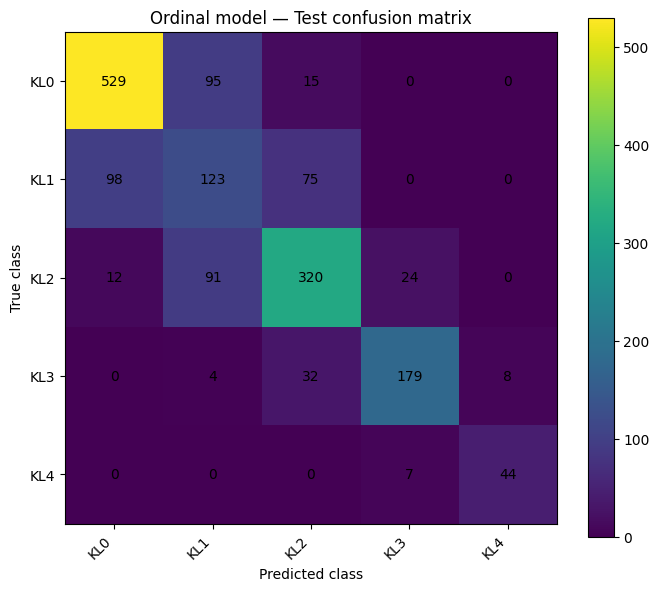

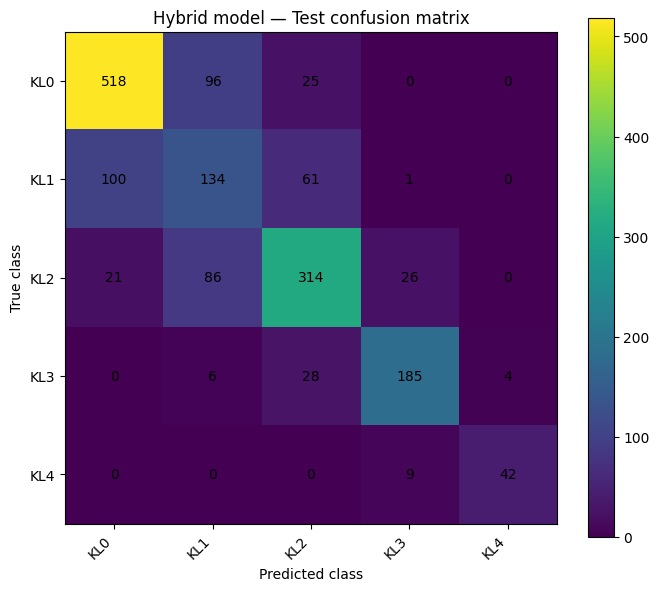

Test images: 1656
Unique filename-derived IDs: 828
auto_test was not loaded or evaluated.
Neither model was fitted or tuned on Test.


In [ ]:
test_dataset = datasets.ImageFolder(
    root=str(DATASET_ROOT / 'test'),
    transform=FEATURE_TRANSFORM,
)
assert test_dataset.class_to_idx == EXPECTED_CLASS_MAPPING, test_dataset.class_to_idx
assert len(test_dataset) == 1656, f'Unexpected Test size: {len(test_dataset)}'

# Parse the participant ID and knee laterality from the documented filename pattern.
cluster_indices = defaultdict(list)
cluster_sides = defaultdict(list)
participant_ids_by_image = []
laterality_by_image = []
filenames_by_image = []

for idx, (image_path, _label) in enumerate(test_dataset.samples):
    filename = Path(image_path).name
    match = re.fullmatch(r'(\d+)([LR])\.png', filename, flags=re.IGNORECASE)
    if match is None:
        raise ValueError(f'Unexpected Test filename pattern: {filename}')
    participant_id, side = match.groups()
    side = side.upper()
    participant_ids_by_image.append(participant_id)
    laterality_by_image.append(side)
    filenames_by_image.append(filename)
    cluster_indices[participant_id].append(idx)
    cluster_sides[participant_id].append(side)

if len(cluster_indices) != 828:
    raise RuntimeError(f'Expected 828 filename-derived IDs; found {len(cluster_indices)}.')
if any(len(indices) != 2 for indices in cluster_indices.values()):
    raise RuntimeError('Expected exactly two Test images per filename-derived ID.')
if any(set(cluster_sides[pid]) != {'L', 'R'} for pid in cluster_sides):
    raise RuntimeError('Expected one L and one R image for each Test ID.')

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(DEVICE.type == 'cuda'),
)

@torch.inference_mode()
def predict_test_and_extract_features(feature_model, loader, device):
    feature_model.eval()
    features_all, labels_all, ordinal_all = [], [], []
    for images, labels in tqdm(loader, desc='Final Test evaluation'):
        images = images.to(device, non_blocking=True)
        logits, features = feature_model(images)
        features_all.append(features.cpu().numpy().astype(np.float32, copy=False))
        labels_all.append(labels.numpy().astype(np.int64, copy=False))
        ordinal_all.append((logits > 0).sum(dim=1).cpu().numpy().astype(np.int64))
    return (
        np.concatenate(features_all),
        np.concatenate(labels_all),
        np.concatenate(ordinal_all),
    )

X_test_features, y_test, y_test_pred_ordinal = predict_test_and_extract_features(
    model, test_loader, DEVICE
)
assert X_test_features.shape == (1656, 768)
assert len(y_test) == len(test_dataset.samples)
assert np.array_equal(np.asarray(test_dataset.targets), y_test)

# Apply already-fitted transformations and classifier only; never fit on Test.
X_test_pca = pca.transform(X_test_features)
y_test_pred_hybrid = best_svm_model.predict(X_test_pca)

assert X_test_pca.shape[1] == pca.n_components_
assert len(y_test_pred_hybrid) == len(y_test)

test_metrics = pd.DataFrame([
    {'Model': 'Direct Ordinal ConvNeXt', **calculate_metrics(y_test, y_test_pred_ordinal)},
    {'Model': 'Proposed Hybrid (PCA + LinearSVC)', **calculate_metrics(y_test, y_test_pred_hybrid)},
])
test_metrics.to_csv(OUTPUT_DIR / 'test_metrics.csv', index=False)
print(test_metrics.round(4).to_string(index=False))

# Save filename-derived participant IDs with predictions for reproducible cluster resampling.
test_predictions = pd.DataFrame({
    'filename': filenames_by_image,
    'participant_id': participant_ids_by_image,
    'laterality': laterality_by_image,
    'true_label': y_test,
    'ordinal_prediction': y_test_pred_ordinal,
    'hybrid_prediction': y_test_pred_hybrid,
})
test_predictions.to_csv(OUTPUT_DIR / 'test_predictions.csv', index=False)

for method_name, predictions in [
    ('ordinal', y_test_pred_ordinal),
    ('hybrid', y_test_pred_hybrid),
]:
    cm = confusion_matrix(y_test, predictions, labels=CLASS_LABELS)
    pd.DataFrame(
        cm,
        index=[f'True_{name}' for name in CLASS_NAMES],
        columns=[f'Pred_{name}' for name in CLASS_NAMES],
    ).to_csv(OUTPUT_DIR / f'test_confusion_matrix_{method_name}.csv')

# Save confusion-matrix figures for the report/repository.
for method_name, predictions in [
    ('ordinal', y_test_pred_ordinal),
    ('hybrid', y_test_pred_hybrid),
]:
    cm = confusion_matrix(y_test, predictions, labels=CLASS_LABELS)
    fig, ax = plt.subplots(figsize=(7, 6))
    image = ax.imshow(cm, interpolation='nearest')
    ax.set_title(f'{method_name.title()} model — Test confusion matrix')
    ax.set_xlabel('Predicted class')
    ax.set_ylabel('True class')
    ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES)
    ax.set_yticks(range(NUM_CLASSES), CLASS_NAMES)
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
    for row in range(cm.shape[0]):
        for col in range(cm.shape[1]):
            ax.text(col, row, str(cm[row, col]), ha='center', va='center')
    fig.colorbar(image, ax=ax)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f'test_confusion_matrix_{method_name}.png', dpi=200, bbox_inches='tight')
    plt.show()
    plt.close(fig)

print('Test images:', len(test_dataset))
print('Unique filename-derived IDs:', len(cluster_indices))
print('auto_test was not loaded or evaluated.')
print('Neither model was fitted or tuned on Test.')

## 9. Test ROC-AUC evaluation

After the model configuration has been selected on Validation, Macro ROC-AUC is calculated on the held-out Test set for both the direct ordinal baseline and the proposed PCA + LinearSVC method. The hybrid AUC uses continuous `LinearSVC.decision_function` scores. For the direct ordinal baseline, isotonic regression is applied to samples with non-monotonic cumulative threshold scores before class-wise AUC is computed; this post-processing is used for AUC scoring only and does not alter the saved hard-label predictions.

The one-vs-rest ROC-AUC is calculated separately for each KL grade, and Macro ROC-AUC is the unweighted mean of the five class-wise values. Test results are reported only; they do not feed back into model selection.

In [ ]:

import numpy as np
import pandas as pd
import torch

from scipy.special import expit
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score

# -------------------------------------------------------
# 1. Collect the four ordinal logits on the Test set
# -------------------------------------------------------
@torch.inference_mode()
def collect_test_ordinal_logits(feature_model, loader, device):
    feature_model.eval()
    logits_list = []
    labels_list = []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)

        logits, _ = feature_model(images)

        logits_list.append(logits.cpu().numpy())
        labels_list.append(labels.numpy())

    return (
        np.concatenate(logits_list, axis=0),
        np.concatenate(labels_list, axis=0),
    )


ordinal_logits_test, y_test_for_auc = collect_test_ordinal_logits(
    model, test_loader, DEVICE
)

# Confirm that the new pass uses exactly the same Test ordering.
assert np.array_equal(y_test_for_auc, y_test)
assert ordinal_logits_test.shape == (len(y_test), 4)

# Check that the re-extracted logits reproduce the existing
# direct ordinal predictions.
predictions_check = (ordinal_logits_test > 0).sum(axis=1)
assert np.array_equal(predictions_check, y_test_pred_ordinal)

# -------------------------------------------------------
# 2. Convert ordinal threshold outputs into class scores
# -------------------------------------------------------
# The four outputs correspond to P(KL > 0), ..., P(KL > 3).
cumulative_probs_raw = expit(ordinal_logits_test)

# Valid cumulative probabilities must be non-increasing:
# P(KL > 0) >= P(KL > 1) >= P(KL > 2) >= P(KL > 3).
violating_rows = np.any(
    np.diff(cumulative_probs_raw, axis=1) > 1e-8,
    axis=1,
)

print("Test images:", len(y_test))
print("Rows with threshold-order violations:", int(violating_rows.sum()))

# If any row violates the expected ordering, use isotonic regression
# on that row's four scores to obtain coherent cumulative probabilities.
# This only derives scores for ROC-AUC; it does not change the
# model, its checkpoint, or the existing hard-label predictions.
cumulative_probs = cumulative_probs_raw.copy()

if violating_rows.any():
    isotonic = IsotonicRegression(
        increasing=False,
        out_of_bounds="clip",
    )
    threshold_positions = np.arange(4)

    for row_idx in np.flatnonzero(violating_rows):
        cumulative_probs[row_idx] = isotonic.fit_transform(
            threshold_positions,
            cumulative_probs_raw[row_idx],
        )

# Derive the five class probabilities from cumulative probabilities:
# P(KL=0) = 1 - P(KL>0)
# P(KL=1) = P(KL>0) - P(KL>1)
# ...
# P(KL=4) = P(KL>3)
direct_class_scores = np.column_stack([
    1.0 - cumulative_probs[:, 0],
    cumulative_probs[:, 0] - cumulative_probs[:, 1],
    cumulative_probs[:, 1] - cumulative_probs[:, 2],
    cumulative_probs[:, 2] - cumulative_probs[:, 3],
    cumulative_probs[:, 3],
])

direct_class_scores = np.clip(direct_class_scores, 0.0, 1.0)
direct_class_scores /= direct_class_scores.sum(axis=1, keepdims=True)

assert direct_class_scores.shape == (len(y_test), 5)
assert np.allclose(direct_class_scores.sum(axis=1), 1.0, atol=1e-6)

# -------------------------------------------------------
# 3. Obtain continuous class scores from the selected LinearSVC
# -------------------------------------------------------
# Use decision_function scores, not hard class predictions.
hybrid_class_scores = best_svm_model.decision_function(X_test_pca)

assert hybrid_class_scores.shape == (len(y_test), 5)
assert np.array_equal(best_svm_model.classes_, CLASS_LABELS)

# -------------------------------------------------------
# 4. Calculate one-vs-rest ROC-AUC for each KL class
# -------------------------------------------------------
auc_rows = []

for class_idx, class_name in enumerate(CLASS_NAMES):
    y_binary = (y_test == class_idx).astype(int)

    auc_direct = roc_auc_score(
        y_binary,
        direct_class_scores[:, class_idx],
    )

    auc_hybrid = roc_auc_score(
        y_binary,
        hybrid_class_scores[:, class_idx],
    )

    auc_rows.append({
        "KL class": class_name,
        "Test support": int(y_binary.sum()),
        "Direct Ordinal ConvNeXt ROC-AUC": auc_direct,
        "Proposed Hybrid ROC-AUC": auc_hybrid,
    })

auc_per_class = pd.DataFrame(auc_rows)

# Macro ROC-AUC = unweighted mean across the five classes.
macro_auc_direct = auc_per_class[
    "Direct Ordinal ConvNeXt ROC-AUC"
].mean()

macro_auc_hybrid = auc_per_class[
    "Proposed Hybrid ROC-AUC"
].mean()

auc_summary = pd.DataFrame([
    {
        "Model": "Direct Ordinal ConvNeXt",
        "Macro ROC-AUC (OvR)": macro_auc_direct,
    },
    {
        "Model": "Proposed Hybrid (PCA + LinearSVC)",
        "Macro ROC-AUC (OvR)": macro_auc_hybrid,
    },
])

print("\nPer-class Test ROC-AUC:")
print(auc_per_class.round(4).to_string(index=False))

print("\nMacro Test ROC-AUC:")
print(auc_summary.round(4).to_string(index=False))

print(
    "\nHybrid minus Direct Macro ROC-AUC:",
    round(macro_auc_hybrid - macro_auc_direct, 4),
)

# -------------------------------------------------------
# 5. Save results for the manuscript and later analysis
# -------------------------------------------------------
auc_per_class.to_csv(
    OUTPUT_DIR / "test_roc_auc_per_class.csv",
    index=False,
)
auc_summary.to_csv(
    OUTPUT_DIR / "test_roc_auc_summary.csv",
    index=False,
)

np.savez_compressed(
    OUTPUT_DIR / "test_roc_auc_scores.npz",
    y_test=y_test,
    ordinal_logits=ordinal_logits_test,
    direct_class_scores=direct_class_scores,
    hybrid_decision_scores=hybrid_class_scores,
)

print("\nROC-AUC results saved to:", OUTPUT_DIR)


Test images: 1656
Rows with threshold-order violations: 217

Per-class Test ROC-AUC:
KL class  Test support  Direct Ordinal ConvNeXt ROC-AUC  Proposed Hybrid ROC-AUC
     KL0           639                           0.9404                   0.9354
     KL1           296                           0.7954                   0.7949
     KL2           447                           0.9239                   0.9159
     KL3           223                           0.9817                   0.9804
     KL4            51                           0.9981                   0.9917

Macro Test ROC-AUC:
                            Model  Macro ROC-AUC (OvR)
          Direct Ordinal ConvNeXt               0.9279
Proposed Hybrid (PCA + LinearSVC)               0.9237

Hybrid minus Direct Macro ROC-AUC: -0.0042

ROC-AUC results saved to: /content/drive/MyDrive/KOA_OrdinalConvNeXt_PCA_SVM_v1_REPRO_TEST


### 9.1. Paired participant-cluster bootstrap for ROC-AUC

The 95% percentile confidence interval for the Test Macro ROC-AUC difference is estimated with 2,000 paired bootstrap replicates. Each replicate samples the 828 filename-derived clusters with replacement and retains both knee images for every sampled ID. Both methods are evaluated on exactly the same resampled observations. No model is refitted, and no hyperparameters are changed during this analysis.

In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score


# Load the continuous Test scores saved by the previous ROC-AUC cell.
saved_scores = np.load(
    OUTPUT_DIR / "test_roc_auc_scores.npz"
)

y_auc_test = saved_scores["y_test"]
test_direct_scores = saved_scores["direct_class_scores"]
test_hybrid_scores = saved_scores["hybrid_decision_scores"]

test_predictions_auc = pd.read_csv(
    OUTPUT_DIR / "test_predictions.csv"
)

assert len(y_auc_test) == 1656
assert np.array_equal(
    y_auc_test,
    test_predictions_auc["true_label"].to_numpy()
)

participant_ids_auc = (
    test_predictions_auc["participant_id"].astype(str).to_numpy()
)
unique_ids_auc = np.unique(participant_ids_auc)

assert len(unique_ids_auc) == 828
assert test_direct_scores.shape == (1656, 5)
assert test_hybrid_scores.shape == (1656, 5)


def macro_auc_ovr(y_true, scores):
    aucs = []

    for class_idx in range(5):
        binary_labels = (y_true == class_idx).astype(int)

        # AUC is undefined if a resample contains only one outcome.
        if np.unique(binary_labels).size < 2:
            return np.nan

        aucs.append(
            roc_auc_score(binary_labels, scores[:, class_idx])
        )

    return float(np.mean(aucs))


# Point estimates for the original Test set.
direct_auc_point = macro_auc_ovr(
    y_auc_test, test_direct_scores
)
hybrid_auc_point = macro_auc_ovr(
    y_auc_test, test_hybrid_scores
)
delta_auc_point = hybrid_auc_point - direct_auc_point

print("Direct Macro ROC-AUC:", round(direct_auc_point, 4))
print("Hybrid Macro ROC-AUC:", round(hybrid_auc_point, 4))
print("Hybrid minus Direct:", round(delta_auc_point, 4))

# Paired participant-level cluster bootstrap.
N_BOOTSTRAP_AUC = 2000
BOOTSTRAP_SEED_AUC = 42
rng_auc = np.random.default_rng(BOOTSTRAP_SEED_AUC)

indices_by_id = {
    pid: np.flatnonzero(participant_ids_auc == pid)
    for pid in unique_ids_auc
}

boot_direct_auc = []
boot_hybrid_auc = []
boot_delta_auc = []

for _ in range(N_BOOTSTRAP_AUC):
    sampled_ids = rng_auc.choice(
        unique_ids_auc,
        size=len(unique_ids_auc),
        replace=True,
    )

    sampled_indices = np.concatenate([
        indices_by_id[pid] for pid in sampled_ids
    ])

    y_boot = y_auc_test[sampled_indices]

    direct_boot = macro_auc_ovr(
        y_boot, test_direct_scores[sampled_indices]
    )
    hybrid_boot = macro_auc_ovr(
        y_boot, test_hybrid_scores[sampled_indices]
    )

    # Both methods must be evaluated on the same resampled IDs.
    if np.isfinite(direct_boot) and np.isfinite(hybrid_boot):
        boot_direct_auc.append(direct_boot)
        boot_hybrid_auc.append(hybrid_boot)
        boot_delta_auc.append(hybrid_boot - direct_boot)

boot_direct_auc = np.asarray(boot_direct_auc)
boot_hybrid_auc = np.asarray(boot_hybrid_auc)
boot_delta_auc = np.asarray(boot_delta_auc)


def percentile_ci(values):
    return np.percentile(values, [2.5, 97.5])


rows = []

for name, point, samples in [
    ("Direct Ordinal ConvNeXt", direct_auc_point, boot_direct_auc),
    ("Proposed Hybrid (PCA + LinearSVC)", hybrid_auc_point, boot_hybrid_auc),
    ("Hybrid minus Direct", delta_auc_point, boot_delta_auc),
]:
    low, high = percentile_ci(samples)

    rows.append({
        "Comparison": name,
        "Macro ROC-AUC or difference": point,
        "CI 95% lower": low,
        "CI 95% upper": high,
        "Valid bootstrap replicates": len(samples),
    })

auc_bootstrap_ci = pd.DataFrame(rows)

print("\nPatient-level paired bootstrap results:")
print(auc_bootstrap_ci.round(4).to_string(index=False))

auc_bootstrap_ci.to_csv(
    OUTPUT_DIR / "test_roc_auc_patient_bootstrap_ci.csv",
    index=False,
)

print(
    "\nSaved to:",
    OUTPUT_DIR / "test_roc_auc_patient_bootstrap_ci.csv",
)


Direct Macro ROC-AUC: 0.9279
Hybrid Macro ROC-AUC: 0.9237
Hybrid minus Direct: -0.0042

Patient-level paired bootstrap results:
                       Comparison  Macro ROC-AUC or difference  CI 95% lower  CI 95% upper  Valid bootstrap replicates
          Direct Ordinal ConvNeXt                       0.9279        0.9197        0.9360                        2000
Proposed Hybrid (PCA + LinearSVC)                       0.9237        0.9154        0.9318                        2000
              Hybrid minus Direct                      -0.0042       -0.0080       -0.0007                        2000

Saved to: /content/drive/MyDrive/KOA_OrdinalConvNeXt_PCA_SVM_v1_REPRO_TEST/test_roc_auc_patient_bootstrap_ci.csv


## 10. Paired patient-level cluster bootstrap for classification metrics

The bootstrap resamples the 828 filename-derived participant clusters with replacement. Both knees/images for a sampled ID remain together, and both methods are evaluated on the same resampled IDs in each replicate. This step uses the saved predictions only; it does not retrain either model or modify any parameters.

The interpretation of the numeric filename prefix as a participant ID follows the dataset's documented naming convention. The bootstrap confidence intervals quantify sampling uncertainty conditional on the saved predictions and the stated cluster definition; they do not by themselves establish external validity.

In [ ]:
N_BOOTSTRAP = 2000
BOOTSTRAP_SEED = 42
rng = np.random.default_rng(BOOTSTRAP_SEED)

# Verify prediction order and IDs before bootstrapping.
assert len(test_predictions) == 1656
assert test_predictions['participant_id'].nunique() == 828
assert np.array_equal(test_predictions['true_label'].to_numpy(), y_test)

participant_ids = np.array(sorted(cluster_indices.keys()))
metric_names = ['Accuracy', 'Macro F1', 'Balanced Accuracy', 'QWK']


def metric_vector(y_true, y_pred):
    return np.array([
        accuracy_score(y_true, y_pred),
        f1_score(y_true, y_pred, labels=CLASS_LABELS, average='macro', zero_division=0),
        balanced_accuracy_score(y_true, y_pred),
        cohen_kappa_score(y_true, y_pred, labels=CLASS_LABELS, weights='quadratic'),
    ], dtype=float)


original_ordinal = metric_vector(y_test, y_test_pred_ordinal)
original_hybrid = metric_vector(y_test, y_test_pred_hybrid)
bootstrap_ordinal = np.empty((N_BOOTSTRAP, len(metric_names)))
bootstrap_hybrid = np.empty((N_BOOTSTRAP, len(metric_names)))
bootstrap_delta = np.empty((N_BOOTSTRAP, len(metric_names)))

for iteration in tqdm(range(N_BOOTSTRAP), desc='Patient-level paired bootstrap'):
    sampled_ids = rng.choice(participant_ids, size=len(participant_ids), replace=True)
    sampled_indices = np.concatenate([
        np.asarray(cluster_indices[participant_id], dtype=int)
        for participant_id in sampled_ids
    ])

    y_boot = y_test[sampled_indices]
    ordinal_boot = y_test_pred_ordinal[sampled_indices]
    hybrid_boot = y_test_pred_hybrid[sampled_indices]

    bootstrap_ordinal[iteration] = metric_vector(y_boot, ordinal_boot)
    bootstrap_hybrid[iteration] = metric_vector(y_boot, hybrid_boot)
    bootstrap_delta[iteration] = bootstrap_hybrid[iteration] - bootstrap_ordinal[iteration]


def summarize_bootstrap(name, point_estimates, bootstrap_values):
    rows = []
    for index, metric_name in enumerate(metric_names):
        low, high = np.percentile(bootstrap_values[:, index], [2.5, 97.5])
        rows.append({
            'Model_or_comparison': name,
            'Metric': metric_name,
            'Original_test_estimate': float(point_estimates[index]),
            'CI_95_lower': float(low),
            'CI_95_upper': float(high),
        })
    return rows


bootstrap_rows = []
bootstrap_rows.extend(summarize_bootstrap('Direct Ordinal ConvNeXt', original_ordinal, bootstrap_ordinal))
bootstrap_rows.extend(summarize_bootstrap('Hybrid (PCA + LinearSVC)', original_hybrid, bootstrap_hybrid))
bootstrap_rows.extend(summarize_bootstrap('Hybrid minus Ordinal', original_hybrid - original_ordinal, bootstrap_delta))
bootstrap_results = pd.DataFrame(bootstrap_rows)
bootstrap_path = OUTPUT_DIR / 'test_bootstrap_patient_level.csv'
bootstrap_results.to_csv(bootstrap_path, index=False)

print(bootstrap_results.round(4).to_string(index=False))
print('\nBootstrap results saved to:', bootstrap_path)

Patient-level paired bootstrap:   0%|          | 0/2000 [00:00<?, ?it/s]

     Model_or_comparison            Metric  Original_test_estimate  CI_95_lower  CI_95_upper
 Direct Ordinal ConvNeXt          Accuracy                  0.7216       0.6993       0.7440
 Direct Ordinal ConvNeXt          Macro F1                  0.7266       0.7018       0.7500
 Direct Ordinal ConvNeXt Balanced Accuracy                  0.7249       0.6988       0.7495
 Direct Ordinal ConvNeXt               QWK                  0.8806       0.8650       0.8945
Hybrid (PCA + LinearSVC)          Accuracy                  0.7204       0.6981       0.7452
Hybrid (PCA + LinearSVC)          Macro F1                  0.7323       0.7088       0.7564
Hybrid (PCA + LinearSVC) Balanced Accuracy                  0.7238       0.6971       0.7509
Hybrid (PCA + LinearSVC)               QWK                  0.8654       0.8485       0.8817
    Hybrid minus Ordinal          Accuracy                 -0.0012      -0.0157       0.0133
    Hybrid minus Ordinal          Macro F1                  0.0057    

## 11. Final saved artifacts and interpretation notes

The results are saved to the Google Drive output directory. The checkpoint, PCA transformation, and selected SVM remain unchanged during Test evaluation and bootstrap. The metadata records that Test was not used for fitting/tuning in this notebook; it also preserves the caveat that some earlier exploratory project experiments used Test labels when developing other configurations.

In [ ]:
METADATA_PATH = OUTPUT_DIR / 'metadata.json'
with open(METADATA_PATH, 'r', encoding='utf-8') as f:
    metadata = json.load(f)

metadata['test_evaluated_in_this_notebook'] = True
metadata['test_evaluation'] = {
    'number_of_images': int(len(y_test)),
    'auto_test_used': False,
    'models': test_metrics.set_index('Model').to_dict(orient='index'),
    'current_run_fitted_or_tuned_on_test': False,
    'historical_caveat': (
        'Some older exploratory experiments used Test labels when tuning other '
        'model configurations. The current notebook selects the PCA/SVM configuration '
        'using Validation and does not fit or tune the selected models on Test.'
    ),
}
metadata['bootstrap'] = {
    'method': 'paired filename-derived participant-level cluster bootstrap',
    'n_replicates': N_BOOTSTRAP,
    'random_seed': BOOTSTRAP_SEED,
    'confidence_interval': '95% percentile bootstrap interval',
    'unique_clusters': int(len(participant_ids)),
    'test_images': int(len(y_test)),
    'models_refit_during_bootstrap': False,
}
metadata['roc_auc_evaluation'] = {
    'averaging': 'macro one-vs-rest across KL0-KL4',
    'used_for_svm_model_selection': False,
    'svm_selection_criterion': 'Validation Macro F1; QWK tie-breaker',
    'direct_ordinal_score_postprocessing': (
        'Sigmoid cumulative scores are made non-increasing with isotonic regression '
        'only for AUC scoring when threshold-order violations occur; hard predictions unchanged.'
    ),
    'validation_threshold_order_violations_direct_model': int(val_violations),
    'test_threshold_order_violations_direct_model': int(violating_rows.sum()),
    'validation_macro_auc_direct': float(val_auc_direct.mean()),
    'validation_macro_auc_hybrid': float(val_auc_hybrid.mean()),
    'test_macro_auc_direct': float(macro_auc_direct),
    'test_macro_auc_hybrid': float(macro_auc_hybrid),
    'test_paired_cluster_bootstrap_ci': auc_bootstrap_ci.to_dict(orient='records'),
}
with open(METADATA_PATH, 'w', encoding='utf-8') as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

expected_artifacts = [
    'pca.joblib', 'linear_svc.joblib', 'extracted_features.npz',
    'validation_metrics.csv', 'validation_predictions.csv',
    'test_metrics.csv', 'test_predictions.csv',
    'test_bootstrap_patient_level.csv', 'metadata.json',
    'test_confusion_matrix_ordinal.csv', 'test_confusion_matrix_hybrid.csv',
    'test_confusion_matrix_ordinal.png', 'test_confusion_matrix_hybrid.png',
    'validation_roc_auc_per_class.csv', 'validation_roc_auc_summary.csv',
    'test_roc_auc_per_class.csv', 'test_roc_auc_summary.csv',
    'test_roc_auc_scores.npz', 'test_roc_auc_patient_bootstrap_ci.csv',
]
missing = [name for name in expected_artifacts if not (OUTPUT_DIR / name).is_file()]
if missing:
    raise FileNotFoundError(f'Missing expected output artifacts: {missing}')

print('All required artifacts are present in:', OUTPUT_DIR)
for name in expected_artifacts:
    path = OUTPUT_DIR / name
    print(f'{name}: {path.stat().st_size / (1024 ** 2):.2f} MB')
print('\nNo model weights or classifier parameters were updated during Test/bootstrap analysis.')